# Clasificación afinada

Ajustamos un transformer (XLM-R diminuto, sin descargas) a una tarea de pares: ¿el texto B es «básico» respecto de A? Es la misma maquinaria que el cross-encoder de prerrequisitos del proyecto, en miniatura. Comparamos con TF-IDF + logística.

In [1]:
import matplotlib.pyplot as plt

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)

In [2]:
WORDS = ["gato", "perro", "casa", "árbol", "río", "sol", "luna", "mar"]


def pairs(n):
    a = [" ".join(rng.choice(WORDS, 4)) for _ in range(n)]
    y = rng.integers(0, 2, n)
    b = [
        ("básico elemental " if t else "avanzado complejo ") + " ".join(rng.choice(WORDS, 3))
        for t in y
    ]
    return a, b, y


(A, B, Y), (VA, VB, VY) = pairs(160), pairs(60)

In [3]:
from research_paths.textclf import TrainConfig, predict_proba, tiny_model, train_classifier

model, tok = tiny_model(A + B)
cfg = TrainConfig(
    model_name="tiny", max_length=64, epochs=6, batch_size=16, lr=3e-3, warmup_ratio=0.0
)
model, tok, history = train_classifier(
    A, Y, VA, VY, cfg, texts_b=B, val_b=VB, model=model, tokenizer=tok
)

/Users/sergiomonsalve/Code/MIA/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  época 1: pérdida 0.6960 · AP val 1.000
  época 2: pérdida 0.6875 · AP val 1.000
  época 3: pérdida 0.5384 · AP val 1.000
  época 4: pérdida 0.2051 · AP val 1.000
  época 5: pérdida 0.0809 · AP val 1.000
  época 6: pérdida 0.0520 · AP val 1.000


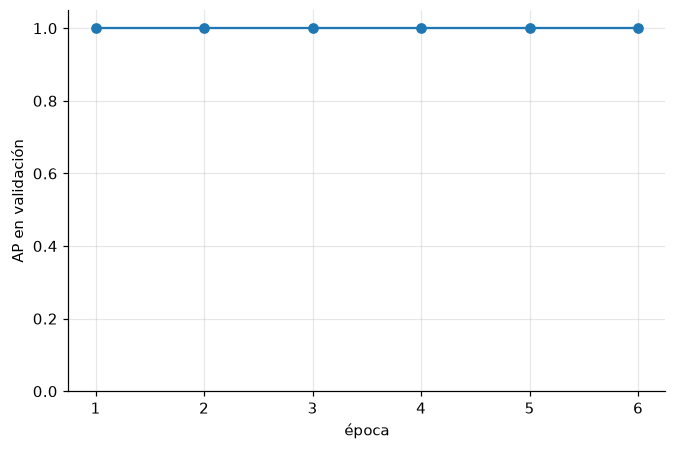

In [4]:
fig, ax = plt.subplots()
ax.plot([h["epoch"] for h in history], [h["val_ap"] for h in history], marker="o")
ax.set(xlabel="época", ylabel="AP en validación", ylim=(0, 1.05));

In [5]:
from research_paths.evaluation import average_precision
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vec = TfidfVectorizer().fit([a + " " + b for a, b in zip(A, B, strict=True)])
clf = LogisticRegression().fit(vec.transform([a + " " + b for a, b in zip(A, B, strict=True)]), Y)
p_tfidf = clf.predict_proba(vec.transform([a + " " + b for a, b in zip(VA, VB, strict=True)]))[:, 1]
p_tr = predict_proba(model, tok, VA, VB, max_length=64)
ap_tfidf, ap_tr = average_precision(VY, p_tfidf), average_precision(VY, p_tr)
print(f"AP TF-IDF: {ap_tfidf:.3f} · AP transformer: {ap_tr:.3f}")

AP TF-IDF: 1.000 · AP transformer: 1.000


Aquí ambos aciertan: la tarea es léxica. En el proyecto la diferencia aparece cuando la relación depende del significado (prerrequisitos) y no de palabras clave.